# 🔍 Phase 2: Systematic Data Exploration & Data Quality Analysis
### UrbanFlow - Smart City Traffic & Accident Analytics

This notebook executes **Phase 2: Data Exploration & Data Quality Analysis** strictly on the raw dataset: `Dataset/raw/indian_roads_dataset.csv`.

---
## Notebook Structure
1. **STEP 2.1**: Complete Dataset Inspection (Dimensions, Schema, Summary Statistics, Ranges)
2. **STEP 2.2**: Data Quality & Boundary Checks (Duplicates, Coordinates, Impossible Values)
3. **STEP 2.3**: Missing Data Analysis (Special Investigation of the `festival` column)
4. **STEP 2.4**: Data Quality Matrix
5. **STEP 2.5**: Initial Frequency & Risk Distributions
6. **STEP 2.6**: Initial Exploratory Visualizations
7. **STEP 2.7**: Output Summary & Key Insights


### 1. Environment Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Load raw dataset
data_path = '../../Dataset/raw/indian_roads_dataset.csv' if os.path.exists('../../Dataset/raw/indian_roads_dataset.csv') else '../Dataset/raw/indian_roads_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'Dataset/raw/indian_roads_dataset.csv'

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")


Dataset successfully loaded from: ../../Dataset/raw/indian_roads_dataset.csv
Dimensions: 20,000 rows x 24 columns


### STEP 2.1: Complete Dataset Inspection

In [2]:
# 1. First 10 Rows
print("--- FIRST 10 ROWS ---")
display(df.head(10))

# 2. Last 10 Rows
print("--- LAST 10 ROWS ---")
display(df.tail(10))

# 3. Data Types & Column Inventory
print("--- COLUMN DATA TYPES ---")
display(pd.DataFrame({'Column': df.columns, 'Dtype': df.dtypes.values, 'Non-Null Count': df.notnull().sum().values}))

# 4. Descriptive Statistics for Numerical Attributes
print("--- NUMERICAL ATTRIBUTES SUMMARY STATISTICS ---")
display(df.describe().round(3).T)

# 5. Missing Values & Percentages
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': null_counts, 'Missing %': null_pct.round(3)})
display(missing_df[missing_df['Missing Count'] > 0])

# 6. Duplication Check
print(f"Total Duplicate Rows: {df.duplicated().sum()}")
print(f"Duplicate Accident IDs: {df['accident_id'].duplicated().sum()}")

# 7. Boundary Ranges
print(f"Date Range: {df['date'].min()} to {df['date'].max()}")
print(f"Latitude Range:  {df['latitude'].min():.6f}° N to {df['latitude'].max():.6f}° N")
print(f"Longitude Range: {df['longitude'].min():.6f}° E to {df['longitude'].max():.6f}° E")
print(f"Risk Score Range: {df['risk_score'].min()} to {df['risk_score'].max()}")
print(f"Casualties Range: {df['casualties'].min()} to {df['casualties'].max()}")
print(f"Vehicles Range:   {df['vehicles_involved'].min()} to {df['vehicles_involved'].max()}")


--- FIRST 10 ROWS ---


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10
5,5,Delhi,Delhi,28.799490,77.049666,2024-07-29,8:00,8,Monday,0,...,high,36,high,overspeeding,fatal,4,4,1,NaN,0.65
6,6,Bangalore,Karnataka,13.064327,77.530941,2025-03-24,6:00,6,Monday,0,...,high,33,high,drunk driving,minor,4,4,0,NaN,0.30
7,7,Chandigarh,Punjab,30.786617,76.733947,2023-05-07,14:00,14,Sunday,1,...,high,25,low,weather,major,3,0,0,NaN,0.10
8,8,Hyderabad,Telangana,17.422447,78.464881,2022-02-25,3:00,3,Friday,0,...,low,22,low,poor road,minor,1,0,0,NaN,0.45
9,9,Bangalore,Karnataka,12.939033,77.498966,2024-03-31,4:00,4,Sunday,1,...,high,23,low,weather,minor,1,0,0,NaN,0.10


--- LAST 10 ROWS ---


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
19990,19990,Pune,Maharashtra,18.438063,73.972270,2022-03-21,2:00,2,Monday,0,...,high,35,medium,poor road,minor,2,2,0,NaN,0.10
19991,19991,Bangalore,Karnataka,13.007009,77.613171,2023-08-17,0:00,0,Thursday,0,...,medium,29,low,weather,minor,2,1,0,NaN,0.25
19992,19992,Pune,Maharashtra,18.698589,73.735182,2023-07-20,6:00,6,Thursday,0,...,low,34,low,weather,minor,4,1,0,NaN,0.45
19993,19993,Mumbai,Maharashtra,18.968212,72.764615,2024-05-05,20:00,20,Sunday,1,...,medium,21,high,weather,major,1,1,0,NaN,0.45
19994,19994,Chandigarh,Punjab,30.653936,76.829248,2023-08-06,2:00,2,Sunday,1,...,low,15,low,drunk driving,minor,2,1,0,NaN,0.45
19995,19995,Bangalore,Karnataka,13.092276,77.599571,2022-09-29,3:00,3,Thursday,0,...,high,31,low,distraction,minor,3,2,0,NaN,0.10
19996,19996,Chennai,Tamil Nadu,13.172928,80.157062,2023-11-25,1:00,1,Saturday,1,...,high,20,low,distraction,major,4,2,0,NaN,0.10
19997,19997,Chennai,Tamil Nadu,12.997170,80.150724,2022-06-18,15:00,15,Saturday,1,...,high,22,low,weather,minor,3,3,0,NaN,0.10
19998,19998,Kolkata,West Bengal,22.454882,88.322213,2023-03-12,4:00,4,Sunday,1,...,high,33,low,poor road,minor,1,0,0,NaN,0.10
19999,19999,Delhi,Delhi,28.510266,77.065301,2024-07-05,23:00,23,Friday,0,...,low,39,high,overspeeding,minor,4,2,0,NaN,0.65


--- COLUMN DATA TYPES ---


,Column,Dtype,Non-Null Count
0,accident_id,int64,20000
1,city,str,20000
2,state,str,20000
3,latitude,float64,20000
4,longitude,float64,20000
5,date,str,20000
6,time,str,20000
7,hour,int64,20000
8,day_of_week,str,20000
9,is_weekend,int64,20000


--- NUMERICAL ATTRIBUTES SUMMARY STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
accident_id,20000.0,9999.500,5773.647,0.0,4999.750,9999.500,14999.250,19999.0
latitude,20000.0,20.389,6.166,12.8,13.199,18.812,28.402,30.8
longitude,20000.0,78.173,4.486,72.7,73.998,77.297,80.111,88.5
hour,20000.0,11.487,6.946,0.0,5.000,12.000,18.000,23.0
is_weekend,20000.0,0.286,0.452,0.0,0.000,0.000,1.000,1.0
lanes,20000.0,3.494,1.705,1.0,2.000,4.000,5.000,6.0
traffic_signal,20000.0,0.500,0.500,0.0,0.000,0.000,1.000,1.0
temperature,20000.0,27.580,7.455,15.0,21.000,28.000,34.000,40.0
vehicles_involved,20000.0,2.992,1.416,1.0,2.000,3.000,4.000,5.0
casualties,20000.0,1.726,1.489,0.0,1.000,1.000,3.000,5.0


,Missing Count,Missing %
festival,19885,99.425


Total Duplicate Rows: 0
Duplicate Accident IDs: 0
Date Range: 2022-01-01 to 2025-04-15
Latitude Range:  12.800172° N to 30.799960° N
Longitude Range: 72.700017° E to 88.499861° E
Risk Score Range: 0.1 to 1.0
Casualties Range: 0 to 5
Vehicles Range:   1 to 5


### STEP 2.2: Data Quality & Boundary Checks

In [3]:
# Check validity of categorical unique values
categorical_cols = ['city', 'state', 'road_type', 'weather', 'visibility', 'traffic_density', 'cause', 'accident_severity']

print("--- UNIQUE CATEGORICAL VALUES ---")
for col in categorical_cols:
    print(f"{col:<18} ({df[col].nunique()} values): {df[col].unique().tolist()}")

# Verify City to State Mapping consistency
print("\n--- CITY TO STATE CORRESPONDENCE ---")
city_state = df.groupby(['city', 'state']).size().unstack().fillna(0).astype(int)
display(city_state)

# Boundary condition tests
print("\n--- DATA INTEGRITY ASSERTION CHECKS ---")
print(f"Invalid hour values (<0 or >23): {((df['hour'] < 0) | (df['hour'] > 23)).sum()}")
print(f"Negative casualties count:       {(df['casualties'] < 0).sum()}")
print(f"Invalid vehicle count (<1):      {(df['vehicles_involved'] < 1).sum()}")
print(f"Invalid lane count (<1):         {(df['lanes'] < 1).sum()}")
print(f"Out-of-range risk scores:        {((df['risk_score'] < 0.0) | (df['risk_score'] > 1.0)).sum()}")


--- UNIQUE CATEGORICAL VALUES ---
city               (8 values): ['Pune', 'Mumbai', 'Chandigarh', 'Chennai', 'Delhi', 'Bangalore', 'Hyderabad', 'Kolkata']
state              (7 values): ['Maharashtra', 'Punjab', 'Tamil Nadu', 'Delhi', 'Karnataka', 'Telangana', 'West Bengal']
road_type          (3 values): ['highway', 'urban', 'rural']
weather            (3 values): ['fog', 'clear', 'rain']
visibility         (3 values): ['low', 'high', 'medium']
traffic_density    (3 values): ['high', 'low', 'medium']
cause              (5 values): ['weather', 'distraction', 'overspeeding', 'drunk driving', 'poor road']
accident_severity  (3 values): ['fatal', 'major', 'minor']

--- CITY TO STATE CORRESPONDENCE ---


state,Delhi,Karnataka,Maharashtra,Punjab,Tamil Nadu,Telangana,West Bengal
city,,,,,,,
Bangalore,0,2438,0,0,0,0,0
Chandigarh,0,0,0,2577,0,0,0
Chennai,0,0,0,0,2575,0,0
Delhi,2433,0,0,0,0,0,0
Hyderabad,0,0,0,0,0,2409,0
Kolkata,0,0,0,0,0,0,2559
Mumbai,0,0,2492,0,0,0,0
Pune,0,0,2517,0,0,0,0



--- DATA INTEGRITY ASSERTION CHECKS ---
Invalid hour values (<0 or >23): 0
Negative casualties count:       0
Invalid vehicle count (<1):      0
Invalid lane count (<1):         0
Out-of-range risk scores:        0


### STEP 2.3: Deep Dive on Missing Data - `festival` Column

In [4]:
fest_nulls = df['festival'].isnull().sum()
fest_pct = (fest_nulls / len(df)) * 100
print(f"Total Missing in 'festival': {fest_nulls:,} out of {len(df):,} records ({fest_pct:.3f}%)")

print("\nNon-null entries count by festival:")
display(df['festival'].value_counts())


Total Missing in 'festival': 19,885 out of 20,000 records (99.425%)

Non-null entries count by festival:


festival
Holi        38
Eid         34
Diwali      31
New Year    12
Name: count, dtype: int64

### STEP 2.5: Initial Frequency & Risk Distributions

In [5]:
print("--- 1. ACCIDENTS BY SEVERITY ---")
display(df['accident_severity'].value_counts())

print("--- 2. ACCIDENTS BY CITY ---")
display(df['city'].value_counts())

print("--- 3. ACCIDENTS BY WEATHER ---")
display(df['weather'].value_counts())

print("--- 4. ACCIDENTS BY ROAD TYPE ---")
display(df['road_type'].value_counts())

print("--- 5. ACCIDENTS BY ROOT CAUSE ---")
display(df['cause'].value_counts())

print("--- 6. ACCIDENTS BY TRAFFIC DENSITY ---")
display(df['traffic_density'].value_counts())

print("--- 7. ACCIDENTS BY DAY OF WEEK ---")
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
display(df['day_of_week'].value_counts()[days_order])

print("--- 8. ACCIDENTS BY PEAK HOUR ---")
display(df['is_peak_hour'].value_counts().rename({0: 'Off-Peak', 1: 'Peak'}))

print("--- 9. ACCIDENTS BY WEEKDAY / WEEKEND ---")
display(df['is_weekend'].value_counts().rename({0: 'Weekday', 1: 'Weekend'}))

print("--- 10. AVERAGE RISK SCORE BY CITY ---")
display(df.groupby('city')['risk_score'].mean().round(4).sort_values(ascending=False))

print("--- 11. AVERAGE RISK SCORE BY SEVERITY ---")
display(df.groupby('accident_severity')['risk_score'].mean().round(4).sort_values(ascending=False))


--- 1. ACCIDENTS BY SEVERITY ---


accident_severity
minor    11025
major     5988
fatal     2987
Name: count, dtype: int64

--- 2. ACCIDENTS BY CITY ---


city
Chandigarh    2577
Chennai       2575
Kolkata       2559
Pune          2517
Mumbai        2492
Bangalore     2438
Delhi         2433
Hyderabad     2409
Name: count, dtype: int64

--- 3. ACCIDENTS BY WEATHER ---


weather
clear    6690
rain     6677
fog      6633
Name: count, dtype: int64

... (12 outputs left out)

--- 10. AVERAGE RISK SCORE BY CITY ---


city
Chandigarh    0.4416
Bangalore     0.4402
Hyderabad     0.4395
Chennai       0.4376
Delhi         0.4371
Pune          0.4358
Kolkata       0.4346
Mumbai        0.4343
Name: risk_score, dtype: float64

--- 11. AVERAGE RISK SCORE BY SEVERITY ---


accident_severity
fatal    0.6075
minor    0.4082
major    0.4068
Name: risk_score, dtype: float64

### STEP 2.6: Initial Exploratory Visualizations

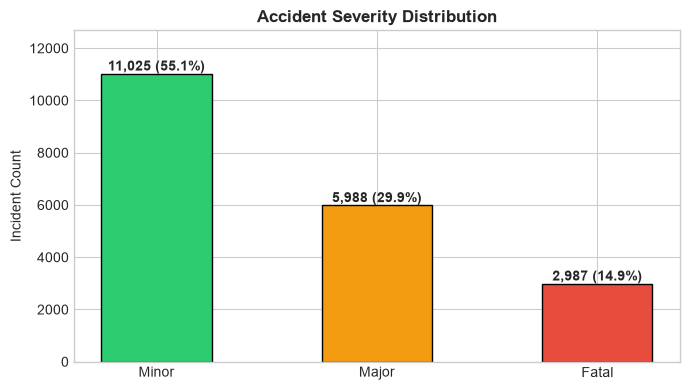

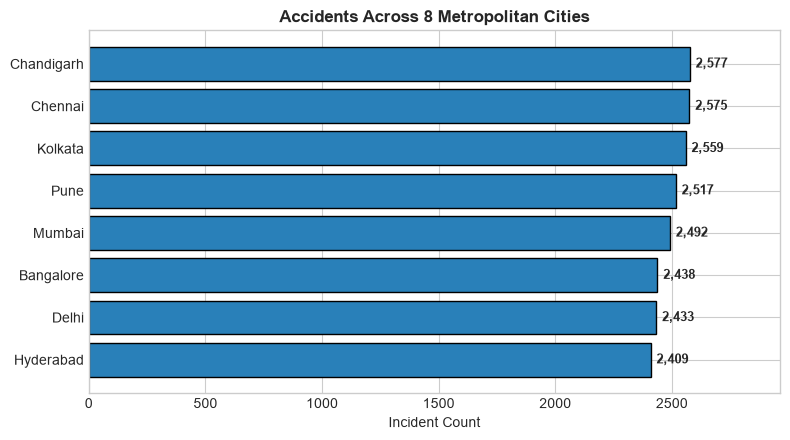

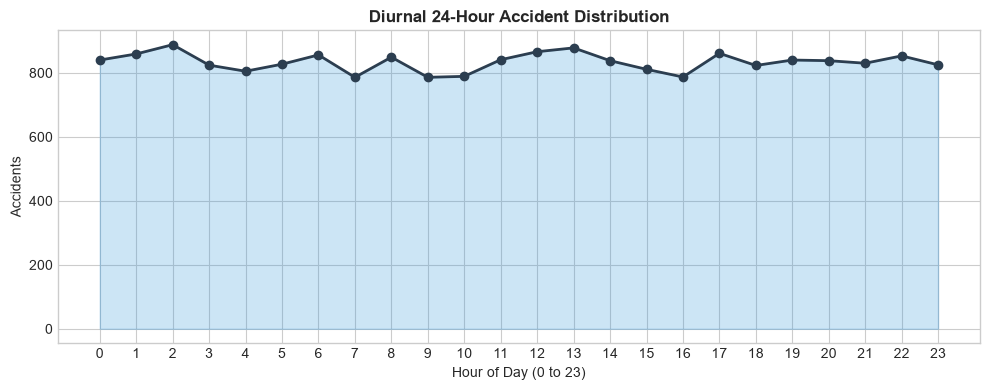

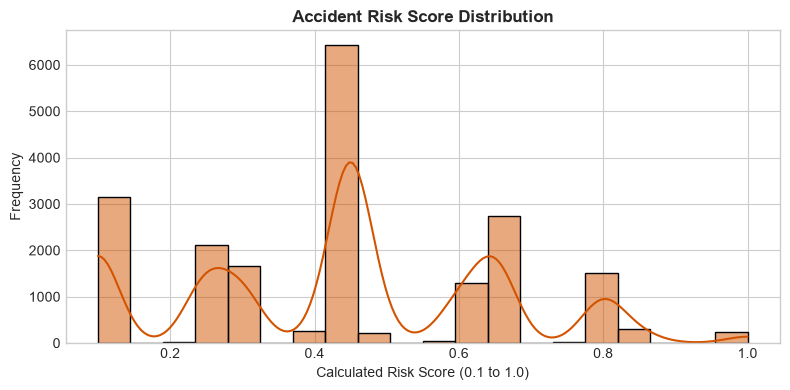

In [6]:
# 1. Severity Distribution
plt.figure(figsize=(7, 4))
sev_counts = df['accident_severity'].value_counts()
plt.bar(sev_counts.index.str.capitalize(), sev_counts.values, color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black', width=0.5)
for i, v in enumerate(sev_counts.values):
    plt.text(i, v + 120, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
plt.title("Accident Severity Distribution", fontweight='bold')
plt.ylabel("Incident Count"); plt.ylim(0, max(sev_counts.values) * 1.15)
plt.tight_layout(); plt.show()

# 2. Accidents by City
plt.figure(figsize=(8, 4.5))
city_counts = df['city'].value_counts().sort_values()
plt.barh(city_counts.index, city_counts.values, color='#2980b9', edgecolor='black')
for i, v in enumerate(city_counts.values):
    plt.text(v + 25, i, f"{v:,}", va='center', fontweight='bold', fontsize=9)
plt.title("Accidents Across 8 Metropolitan Cities", fontweight='bold')
plt.xlabel("Incident Count"); plt.xlim(0, city_counts.max() * 1.15)
plt.tight_layout(); plt.show()

# 3. Hourly Diurnal Curve
plt.figure(figsize=(10, 4))
hourly = df['hour'].value_counts().sort_index()
plt.plot(hourly.index, hourly.values, marker='o', color='#2c3e50', linewidth=2)
plt.fill_between(hourly.index, hourly.values, color='#3498db', alpha=0.25)
plt.title("Diurnal 24-Hour Accident Distribution", fontweight='bold')
plt.xlabel("Hour of Day (0 to 23)"); plt.ylabel("Accidents")
plt.xticks(range(0, 24))
plt.tight_layout(); plt.show()

# 4. Risk Score Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['risk_score'], bins=20, kde=True, color='#d35400', edgecolor='black')
plt.title("Accident Risk Score Distribution", fontweight='bold')
plt.xlabel("Calculated Risk Score (0.1 to 1.0)"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()
